**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_031_초급_다중분류_자동차보험청구분석

### **자동차보험 청구 분석 — <span style="color:darkgreen">사고 심각도</span> 예측 모델 개발**
---

- 도메인 : 자동차보험 청구 분석
- 목  표 : 사고 심각도를 3단계로 예측하는 인공지능모델 개발
- 부정 청구로 인한 보험금 누수가 늘어 초록다이렉트의 손해율이 악화되고 있다.
- 보상팀은 청구 정보를 분석해 의심 건을 우선 조사하려 한다.
- 청구 건 1,830건 안팎의 이력 데이터를 활용할 수 있다.
- 초록다이렉트는 사고 심각도를 정확히 예측할 수 있다면 의사결정의 속도와 정확도를 함께 높일 수 있을 것으로 기대하고 있다.

---

#### **[유의사항]**
- 각 문항의 답은 `# (번호) 정답을 입력하세요` 셀의 `정답01` ~ `정답14` 변수에 **값만** 입력합니다. 채점은 이 값으로만 합니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 초록다이렉트의 데이터로 사고 심각도를 3단계로 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, quantile, reset_index, drop, copy, fillna, mean, sum, isnull, get_dummies, DataFrame, sort_values, columns, shape) · seaborn(import seaborn as sns, countplot, histplot, barplot) · matplotlib(show) · scikit-learn(LabelEncoder, fit_transform, train_test_split, StandardScaler, transform, DecisionTreeClassifier, fit, RandomForestClassifier, feature_importances_, predict, accuracy_score) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, Dense, Dropout, evaluate)
- 난이도 : 초급 (설계 난이도 점수 2.51 / 5)
- 예상 소요 시간 : 약 116분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 자동차보험 청구 분석 (금융·보험)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- REG_NO                : 등록번호
- CLAIM_AMOUNT          : 청구 금액(만원)
- POLICY_AGE            : 보험 가입 기간(개월)
- N_CLAIMS_PREV         : 과거 청구 횟수
- DRIVER_AGE            : 운전자 연령(세)
- VEHICLE_VALUE         : 차량 가액(만원)
- ANNUAL_KM             : 연간 주행거리(천km)
- REPAIR_EST            : 정비 견적(만원)
- REPORT_DELAY_D        : 사고 접수 지연(일)
- WITNESS_CNT           : 목격자 수
- PREMIUM_KRW           : 연 보험료(만원)
- COVERAGE              : 담보 유형
- CHANNEL               : 가입 채널
- REGION                : 사고 지역
- SEVERITY              : 사고 심각도 (0: Minor, 1: Moderate, 2: Severe)

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### **1. 분석에 필요한 라이브러리 두 개를 아래 가이드의 별칭으로 한 번에 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd) · seaborn(import seaborn as sns) | 난이도: 기초 | 예상 시간: 3분</sub>

- `seaborn` 은(는) `sns` 라는 이름으로
- `pandas` 은(는) `pd` 라는 이름으로
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 답안 셀에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [2]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import seaborn as sns
import pandas as pd

In [3]:
# (1) 정답을 입력하세요 — `정답01` 에 값만 넣고 실행하세요

정답01 = 'seaborn'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

라이브러리마다 import 문을 따로 작성하고 각각 별칭을 붙입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 7글자이고 첫 글자는 `s` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seab___ as sns
import pandas as pd

정답01 = 'seab___'   # 빈칸에 넣은 단어
```

</details>

### **2. 모델링에 사용할 데이터 파일을 불러오려고 합니다. 아래 안내대로 파일을 읽어 df_raw 에 저장하고 처음 3개 행을 확인하십시오.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 아래 안내대로 코드를 작성하고 실행하세요
    - 읽어 올 파일 : data.csv
    - 파일은 본 문제/답안지와 동일한 경로에 있습니다
    - 읽은 결과를 담을 변수 : df_raw
- **[정답02]** 읽어 온 데이터의 **행(row)의 개수** 를 기입하세요
- 답안 : **[정답02]** 의 값만 답안 셀에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [7]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
import pandas as pd

df_raw = pd.read_csv('./data.csv')
df_raw.head(3)

print(df_raw.shape[0])



1830


In [8]:
# (2) 정답을 입력하세요 — `정답02` 에 값만 넣고 실행하세요

정답02 = 1830

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요. 읽어 온 df_raw 로 행(row)의 개수를 직접 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`, `shape`, `select_dtypes`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df_raw = pd.read_csv('./data.csv')
df_raw.head(3)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
print(df_raw.shape[__])
```

</details>

### **3. 시각화를 통해 담보 유형(COVERAGE)의 분포를 파악할 계획입니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(countplot) · matplotlib(show) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 1번 `sns` · 2번 `df_raw`
- 다음 지침에 따라 seaborn 라이브러리를 활용해서 시각화하세요
    - 대상 데이터프레임 : df_raw
    - 담보 유형(COVERAGE)의 분포를 보여주는 countplot 그래프를 그리세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 답안 셀에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47932 (\N{HANGUL SYLLABLE MUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

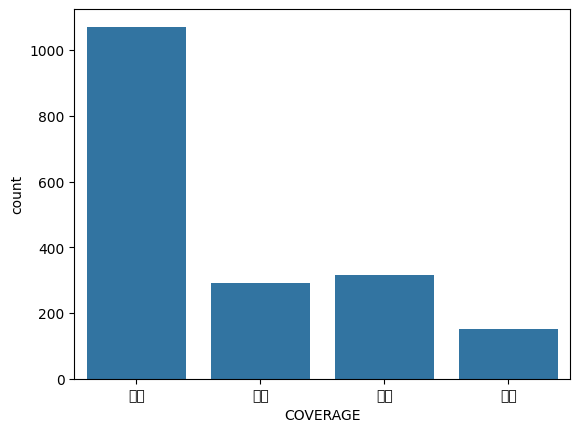

In [9]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.countplot(data=df_raw, x='COVERAGE')
plt.show()

In [10]:
# (3) 정답을 입력하세요 — `정답03` 에 값만 넣고 실행하세요

정답03 = 'countplot'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

범주형 변수의 값별 개수를 막대로 그리는 seaborn 함수를 고르세요. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `sns.countplot`. 정답은 9글자이고 첫 글자는 `c` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.count____(data=df_raw, x='COVERAGE')
plt.show()

정답03 = 'count____'   # 빈칸에 넣은 단어
```

</details>

### **4. 목격자 수(WITNESS_CNT)의 분포를 가입 채널 별로 나누어 확인할 계획입니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(histplot) · matplotlib(show) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 1번 `sns` · 2번 `df_raw`
- 대상 데이터프레임 : df_raw
- seaborn 의 histplot 으로 WITNESS_CNT 의 분포를 그리세요
- CHANNEL 로 색상을 구분(hue)하세요
- 구간 수(bins)는 40, 막대 표시 방식(multiple)은 'stack' 로 지정하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 답안 셀에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49444 (\N{HANGUL SYLLABLE SEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 55092 (\N{HANGUL SYLLABLE HYU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/l

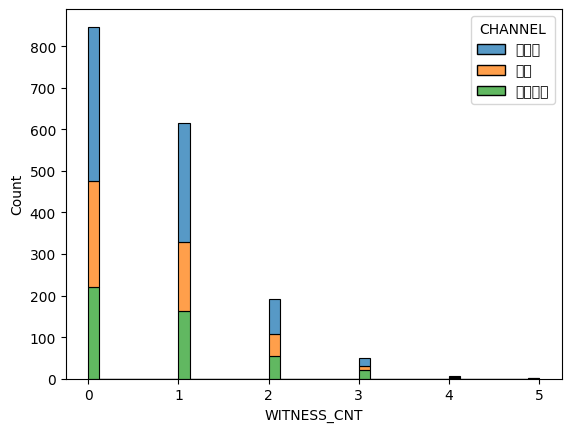

In [11]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.histplot(data=df_raw, x='WITNESS_CNT', hue='CHANNEL', bins=40, multiple='stack')
plt.show()

In [12]:
# (4) 정답을 입력하세요 — `정답04` 에 값만 넣고 실행하세요

정답04 = 'multiple'

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

수치형 변수의 분포를 그룹별로 나누어 히스토그램으로 그립니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `sns.histplot`. 정답은 8글자이고 첫 글자는 `m` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df_raw, x='WITNESS_CNT', hue='CHANNEL', bins=40, mult____='stack')
plt.show()

정답04 = 'mult____'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 과거 청구 횟수(N_CLAIMS_PREV) 컬럼의 이상치를 IQR 기준으로 제거할 계획입니다. 다음 지침에 따라 처리하세요.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, reset_index, drop) | 난이도: 보통 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 대상 데이터프레임 : df_raw
- 사분위수(Q1, Q3)와 IQR 을 계산하세요
- lower_fence = Q1 - 2.0 x IQR, upper_fence = Q3 + 2.0 x IQR 로 정의하세요
- N_CLAIMS_PREV 이(가) 두 fence 밖에 있는 행을 삭제하세요
- 식별자 컬럼 REG_NO 도 삭제하고 인덱스를 0부터 다시 매겨 df_clean 에 담으세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답05]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답05]** 의 값만 답안 셀에 `정답05 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [13]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

q1 = df_raw['N_CLAIMS_PREV'].quantile(0.25)
q3 = df_raw['N_CLAIMS_PREV'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 2.0 * iqr
upper_fence = q3 + 2.0 * iqr

is_out = (df_raw['N_CLAIMS_PREV'] > upper_fence) | (df_raw['N_CLAIMS_PREV'] < lower_fence)
df_clean = df_raw[~is_out].drop(columns=['REG_NO']).reset_index(drop=True)

In [14]:
# (5) 정답을 입력하세요 — `정답05` 에 값만 넣고 실행하세요

정답05 = 'quantile'

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

분위수로 fence 를 계산하고, 범위 밖 여부를 불리언으로 만든 뒤 반대로 선택합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `quantile`, `drop`, `reset_index`. 정답은 8글자이고 첫 글자는 `q` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
q1 = df_raw['N_CLAIMS_PREV'].quan____(0.25)
q3 = df_raw['N_CLAIMS_PREV'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 2.0 * iqr
upper_fence = q3 + 2.0 * iqr

is_out = (df_raw['N_CLAIMS_PREV'] > upper_fence) | (df_raw['N_CLAIMS_PREV'] < lower_fence)
df_clean = df_raw[~is_out].drop(columns=['REG_NO']).reset_index(drop=True)

정답05 = 'quan____'   # 빈칸에 넣은 단어
```

</details>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다. 아래 가이드에 따라 결측치를 확인하고 처리하십시오.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(copy, fillna, mean, sum) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 5번 `df_clean`
- 대상 데이터프레임 : df_clean
- 다음 지침에 따라 결측치를 처리하고 검증하는데 에러가 나고 있습니다. 코드의 오류를 바로잡으세요
    - 수치형 컬럼(ANNUAL_KM, WITNESS_CNT)의 결측치는 **평균** 으로 채우세요
    - 처리가 반영된 데이터프레임은 변수명 df_filled 에 저장하고, 남은 결측치 개수를 출력하세요
- **[정답06]** 처리 전 df_clean 의 결측치는 총 몇 개입니까?
- 답안 : **[정답06]** 의 값만 답안 셀에 `정답06 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [16]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

df_filled = df_clean.copy()
df_filled['ANNUAL_KM'] = df_filled['ANNUAL_KM'].fillna(df_filled['ANNUAL_KM'].mean())
df_filled['WITNESS_CNT'] = df_filled['WITNESS_CNT'].fillna(df_filled['WITNESS_CNT'].mean())
print(df_filled.isnull().sum().sum())
df_clean.isnull().sum().sum()

0


np.int64(416)

In [ ]:
# (6) 정답을 입력하세요 — `정답06` 에 값만 넣고 실행하세요

정답06 = 416

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

결측치를 평균/최빈값으로 채우는 흐름을 점검하세요. 결측치 처리 전 데이터프레임의 결측치 합계를 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
df_filled = df_clean.copy()
df_filled['ANNUAL_KM'] = df_filled['ANNUAL_KM'].fillna(df_filled['ANNUAL_KM'].mean())
df_filled['WITNESS_CNT'] = df_filled['WITNESS_CNT'].fillna(df_filled['WITNESS_CNT'].mean())
print(df_filled.isnull().sum().sum())

# [정답06] 실행한 결과를 입력하세요
df_clean.isnull().sum().sum()
```

</details>

### **7. 범주형 컬럼의 특성에 따라 인코딩 방식을 달리 적용할 계획입니다. 다음 지침에 따라 인코딩하십시오.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(copy, get_dummies) · scikit-learn(LabelEncoder, fit_transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `df_filled`
- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_filled
    - 사고 지역(REGION) 는 sklearn **LabelEncoder** 로 정수 인코딩하세요
    - 나머지 문자열 컬럼 COVERAGE, CHANNEL 은(는) get_dummies(drop_first=True)로 원-핫 인코딩하세요
    - 결과는 df_final 에 저장하세요
- **[정답07]** 인코딩 후 df_final 의 **전체 컬럼 개수**는 몇 개인가요?
- 답안 : **[정답07]** 의 값만 답안 셀에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [20]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
from sklearn.preprocessing import LabelEncoder

df_final = df_filled.copy()
le = LabelEncoder()
df_final['REGION'] = le.fit_transform(df_final['REGION'])
df_final = pd.get_dummies(data = df_final, columns=['COVERAGE', 'CHANNEL'], drop_first=True)
df_final.shape[1]


17

In [ ]:
# (7) 정답을 입력하세요 — `정답07` 에 값만 넣고 실행하세요

정답07 = None

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

한 컬럼은 정수 라벨로, 나머지는 0/1 컬럼으로 바꿉니다. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `LabelEncoder`, `fit_transform`, `pd.get_dummies`, `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

from sklearn.preprocessing import LabelEncoder

df_final = df_filled.copy()
le = LabelEncoder()
df_final['REGION'] = le.fit_transform(df_final['REGION'])
df_final = pd.get_dummies(data=df_final, columns=['COVERAGE', 'CHANNEL'], drop_first=True)

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
df_final.shape[__]
```

</details>

### **8. 학습한 모델을 공정하게 평가하려면 학습에 쓰지 않은 검증 데이터가 필요합니다. 데이터를 훈련용과 검증용으로 나누려 합니다. 제시된 가이드에 맞춰 분리하십시오.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 7번 `df_final`
- 대상 데이터프레임 : df_final
- 사고 심각도(SEVERITY) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 지정하세요
- 훈련과 검증 데이터셋 분리 — 훈련 : 검증 = 85:15 (train_size=0.85)
- 분리 결과는 X_train, X_valid, y_train, y_valid 순서로 받으세요 / train_test_split 함수(scikit-learn)로 나누세요
- 클래스 비율을 유지하는 층화 추출(stratify=y)을 적용하세요
- 결과를 재현할 수 있게 random_state 값을 7 로 지정하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답08]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답08]** 의 값만 답안 셀에 `정답08 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [22]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

from sklearn.model_selection import train_test_split

X = df_final.drop('SEVERITY', axis=1)
y = df_final['SEVERITY']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.85, random_state=7, stratify=y)

In [23]:
# (8) 정답을 입력하세요 — `정답08` 에 값만 넣고 실행하세요

정답08 = 'train_size'

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`. 정답은 10글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
from sklearn.model_selection import train_test_split

X = df_final.drop('SEVERITY', axis=1)
y = df_final['SEVERITY']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_____=0.85, random_state=7, stratify=y)

정답08 = 'train_____'   # 빈칸에 넣은 단어
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (표준화(평균 0, 표준편차 1))**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(StandardScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 아래 안내대로 스케일링 처리하는데 에러가 나고 있습니다. 코드의 오류를 바로잡으세요
    - sklearn.preprocessing 에서 StandardScaler 를 import 하세요
    - StandardScaler 를 scaler 변수에 설정하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 보관하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 보관하세요
- **[정답09]** StandardScaler 적용 후 검증 데이터(X_valid)의 **최솟값**을 소수 둘째 자리까지 작성하세요
- 답안 : **[정답09]** 의 값만 답안 셀에 `정답09 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [26]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)
print(X_valid.min())

-2.511872249067952


In [27]:
# (9) 정답을 입력하세요 — `정답09` 에 값만 넣고 실행하세요

정답09 = -2.51

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최솟값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.min`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.min(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 사고 심각도(SEVERITY)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. DecisionTree와(과) RandomForest는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(DecisionTreeClassifier, fit, RandomForestClassifier) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- DecisionTree 모델을 아래와 같이 만들어 `dt` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : max_depth=8, min_samples_leaf=10
    - 난수 시드(random_state) : 0
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- RandomForest 모델을 아래와 같이 만들어 `rf` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_estimators=200, max_depth=10
    - 난수 시드(random_state) : 0
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `dt`(DecisionTree) 의 **잎(leaf) 노드 수** `dt.get_n_leaves()` 는 몇 개입니까?
- 답안 : **[정답10]** 의 값만 답안 셀에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [30]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

dt = DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=0)
dt.fit(X_train, y_train)

rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=0)
rf.fit(X_train, y_train)

print(dt.get_n_leaves())

77


In [ ]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)



In [31]:
# (10) 정답을 입력하세요 — `정답10` 에 값만 넣고 실행하세요

정답10 = 77

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 결정나무 모델의 get_n_leaves() 메서드를 호출하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `DecisionTreeClassifier`, `fit`, `RandomForestClassifier`, `get_n_leaves`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=0)
dt.fit(X_train, y_train)

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=0)
rf.fit(X_train, y_train)

# [정답10] 실행한 결과를 입력하세요
dt.get_n_leaves()
```

</details>

### **11. 모델의 해석력과 개선 방향을 이해하기 위해 RandomForest 모델의 변수중요도를 파악하려고 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(DataFrame, sort_values, columns) · seaborn(barplot) · matplotlib(show) · scikit-learn(feature_importances_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd`, `sns` · 8번 `X` · 10번 `rf`
- 아래 안내대로 모델의 변수중요도를 파악하는데 실행 중 예외가 발생합니다. 코드의 오류를 바로잡으세요
    - 앞서 학습시킨 RandomForest 모델 `rf` 를 사용하세요
    - 변수중요도 점수와 변수 이름(X.columns)을 매핑하여 DataFrame(fi)을 만드세요
    - 변수중요도 점수를 기준으로 내림차순 정렬하고 Top 8 개만 선정하세요
    - 변수중요도 점수를 막대 그래프(seaborn barplot)로 시각화하세요
- **[정답11]** 출력된 그래프에서 **가장 높은 중요도**를 보이는 변수명을 쓰세요
- 답안 : **[정답11]** 의 값만 답안 셀에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

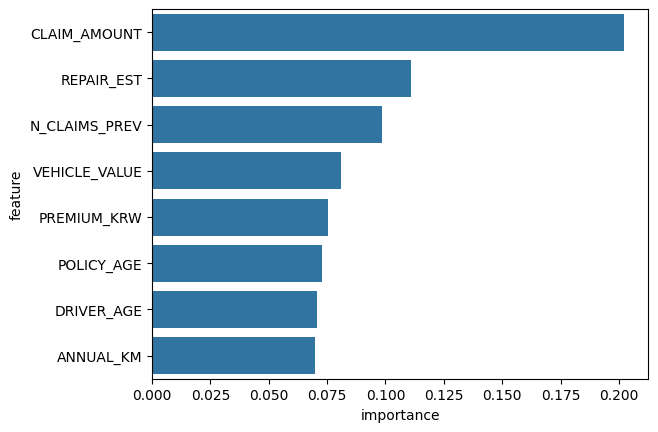

In [34]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:8]
sns.barplot(x='importance', y='feature', data=fi)
plt.show()

In [35]:
# (11) 정답을 입력하세요 — `정답11` 에 값만 넣고 실행하세요

정답11 = 'CLAIM_AMOUNT'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

변수 중요도를 DataFrame 으로 만들고 정렬해 그리는 흐름을 점검하세요. fi 의 첫 번째 행(가장 큰 중요도)의 feature 값을 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `sort_values`, `iloc`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:8]
sns.barplot(x='importance', y='feature', data=fi)
plt.show()

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
fi['____'].iloc[__]
```

</details>

### **12. 앞서 학습시킨 DecisionTree와(과) RandomForest 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, accuracy_score) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `dt`, `rf`
- 아래 가이드에 따라 각 모델의 Accuracy(정확도) 를 산출하려는데 오류가 발생하고 있습니다. 코드의 오류를 수정하세요
    - 앞서 학습시킨 dt 와 rf 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 Accuracy(정확도) 값을 각각 dt_score, rf_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 Accuracy(정확도) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (DecisionTree / RandomForest 중 하나)
- 답안 : **[정답12]** 의 값만 답안 셀에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [36]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import accuracy_score

y_pred_dt = dt.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

dt_score = accuracy_score(y_valid, y_pred_dt)
rf_score = accuracy_score(y_valid, y_pred_rf)
print(dt_score, rf_score)

0.4888888888888889 0.5370370370370371


In [38]:
# (12) 정답을 입력하세요 — `정답12` 에 값만 넣고 실행하세요

정답12 = "RandomForest"

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

Accuracy(정확도) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 클수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import accuracy_score

y_pred_dt = dt.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

dt_score = accuracy_score(y_valid, y_pred_dt)
rf_score = accuracy_score(y_valid, y_pred_rf)
print(dt_score, rf_score)

# [정답12] 실행한 결과를 입력하세요
print(dt_score, rf_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [39]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(7)

### **13. 사고 심각도(SEVERITY)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 아래 조건대로 모델을 만들고 학습시키세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 보통 | 예상 시간: 13분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- 딥러닝 프레임워크는 tensorflow 를 씁니다
- Dense 은닉층 2개를 노드 수 [64, 32] 순서로 쌓고, 활성화 함수는 'selu' 를 쓰세요
- 은닉층마다 뒤에 Dropout(0.2) 을 붙이세요
- EarlyStopping 으로 20번의 epoch 동안 val_loss 가 향상되지 않으면 훈련을 중지(restore_best_weights=True)하도록 설정하고 estop 변수에 저장하세요
- 출력층은 노드 3개, activation='softmax' 로 하세요
- optimizer 는 adam, loss 는 sparse_categorical_crossentropy, metrics 는 [accuracy] 로 지정해서 모델을 컴파일하세요
- batch_size 는 16, epochs 는 30 로 학습하고 학습정보는 history 변수에 저장하세요 (검증 데이터: X_valid, 검증 레이블)
- 안내된 내용 외 별도의 파라미터를 입력하지 마세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답13]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답13]** 의 값만 답안 셀에 `정답13 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [40]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

model = Sequential([
    Dense(64, activation='selu', input_dim=X_train.shape[1]),
    Dropout(0.2),
    Dense(32, activation='selu'),
    Dropout(0.2),
    Dense(3, activation='softmax')
])

estop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=16,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.4728 - loss: 1.1873 - val_accuracy: 0.5815 - val_loss: 0.8675
Epoch 2/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5587 - loss: 0.9418 - val_accuracy: 0.5815 - val_loss: 0.8576
Epoch 3/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5731 - loss: 0.8781 - val_accuracy: 0.5963 - val_loss: 0.8602
Epoch 4/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6013 - loss: 0.8528 - val_accuracy: 0.5963 - val_loss: 0.8630
Epoch 5/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5869 - loss: 0.8711 - val_accuracy: 0.5852 - val_loss: 0.8600
Epoch 6/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5915 - loss: 0.8391 - val_accuracy: 0.5815 - val_loss: 0.8491
Epoch 7/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5941 - loss: 0.8230 - val_accuracy: 0.5815 - val_loss: 0.8585
Epoch 8/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6190 - loss: 0.8276 - val_accuracy: 0.5852 - val_los

In [41]:
# (13) 정답을 입력하세요 — `정답13` 에 값만 넣고 실행하세요

정답13 = 'sparse_categorical_croseentropy'

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드의 모델 구조·학습 조건을 코드의 각 줄과 대응시켜 보세요. 예측과 정답의 차이를 재는 손실 함수의 이름입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`. 정답은 31글자이고 첫 글자는 `s` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
model = Sequential([
    Dense(64, activation='selu', input_dim=X_train.shape[1]),
    Dropout(0.2),
    Dense(32, activation='selu'),
    Dropout(0.2),
    Dense(3, activation='softmax')
])

estop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='adam', loss='sparse_categoric_______________', metrics=['accuracy'])

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=16,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

정답13 = 'sparse_categoric_______________'   # 빈칸에 넣은 단어
```

</details>

### **14. 학습이 끝난 모델의 최종 성능을 검증 데이터로 한 번 더 확인하려 합니다.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: TensorFlow(Keras)(evaluate) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 13번 `model`
- 학습된 `model` 의 `evaluate` 로 검증 데이터(X_valid, y_valid)의 성능을 계산하세요 (verbose=0)
    - 반환되는 값은 loss 와 compile 에서 지정한 metrics(accuracy) 순서입니다. 각각 `loss, accuracy` 변수에 저장하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답14]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답14]** 의 값만 답안 셀에 `정답14 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [42]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

loss, accuracy = model.evaluate(X_valid, y_valid, verbose=0)

In [43]:
# (14) 정답을 입력하세요 — `정답14` 에 값만 넣고 실행하세요

정답14 = 'evaluate'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

학습된 모델에 검증 데이터를 넣어 손실과 지표를 한 번에 구합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `model.evaluate`. 정답은 8글자이고 첫 글자는 `e` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
loss, accuracy = model.eval____(X_valid, y_valid, verbose=0)

정답14 = 'eval____'   # 빈칸에 넣은 단어
```

</details>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### 답안을 저장한 뒤 제출해 주시기 바랍니다.